In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 200)

In [14]:
df = pd.read_csv('bank_customers.csv', sep=';')

In [ ]:
%pip install scipy

In [7]:
df.shape

(4521, 17)

In [ ]:
df.head(5)

In [ ]:
df.columns

In [ ]:
df.dtypes


In [ ]:
df.describe().round(2)

In [ ]:
# Example of dropping columns
df = df.drop(['duration'], axis=1, errors='ignore')
df.columns

In [ ]:
# =====================================
# SELECT SPECIFIC COLUMNS FOR ANALYSIS
# =====================================

df = df[['age',
         'job',
         'marital',
         'education',
         'default',
         'balance',
         'housing',
         'loan',
         'contact',
         'day',
         'month',
        #  'duration',
         'campaign',
         'pdays',
         'previous',
        #  'poutcome',
         'y']].copy()

In [ ]:
df.head()

In [23]:
# Convert month into a categorical data type
df['month'] = df['month'].astype('category')

In [ ]:
df.isna().sum()

In [ ]:
# Check for duplicate coaster name
df.loc[df.duplicated(subset=['job'])].head(5)

In [ ]:

# Checking an example duplicate
df.query('job == "management"')

In [27]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous',
       'y'],
      dtype='str')

In [ ]:
#Remove duplicates on selected columns
df = df.loc[~df.duplicated(subset=['month','job','contact'])] \
    .reset_index(drop=True).copy()



In [ ]:
df['month'].value_counts()

In [ ]:
ax = df['job'].value_counts() \
    .head(10) \
    .plot(kind='bar', title='Top 10 Jobs by Number of Customers')

ax.set_xlabel('Job')
ax.set_ylabel('Number of Customers')

In [ ]:
ax = df['balance'].plot(kind='hist',
                        bins=20,
                        title='Distribution of Customer Bank Balances')

ax.set_xlabel('Account Balance')
ax.set_ylabel('Number of Customers')

Text(0.5, 0, 'Account Balance')

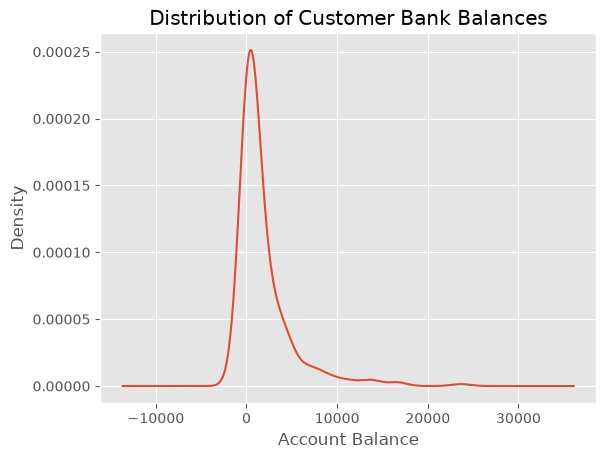

In [38]:
# Create a KDE plot for customer bank balances
ax = df['balance'].plot(
    kind='kde',
    title='Distribution of Customer Bank Balances'
)

# Label the x-axis
ax.set_xlabel('Account Balance')

In [ ]:
print(df.columns.tolist())

In [ ]:
df['job'].value_counts()


In [ ]:
# Compare customer bank balance with age
df.plot(
    kind='scatter',
    x='balance',
    y='age',
    title='Bank Balance vs. Age'
)

plt.show()

In [ ]:
# Create a scatter plot showing bank balance vs age
ax = sns.scatterplot(
    x='balance',
    y='age',
    hue='y',
    data=df
)

# Add chart title
ax.set_title('Bank Balance vs. Age by Subscription Status')

plt.show()

In [46]:
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'y']


In [ ]:
# Create pair plots to compare numerical variables
sns.pairplot(
    df,
    vars=['age', 'balance', 'day', 'campaign', 'previous'],
    hue='y'
)

plt.show()

In [ ]:
# Select numerical columns and calculate their correlations
df_corr = df[['age', 'balance', 'day',
              'campaign', 'previous']].dropna().corr()

# Display the correlation matrix
df_corr

In [ ]:
# Create a correlation heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    df_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

# Add chart title
plt.title('Correlation Heatmap of Bank Marketing Variables')

plt.show()

In [ ]:
# Calculate average bank balance by job category
ax = df.query('job != "unknown"') \
    .groupby('job')['balance'] \
    .agg(['mean', 'count']) \
    .query('count >= 10') \
    .sort_values('mean')['mean'] \
    .plot(
        kind='barh',
        figsize=(12, 5),
        title='Average Bank Balance by Job Category'
    )

# Label the x-axis
ax.set_xlabel('Average Bank Balance')

# Display the chart
plt.show()

In [ ]:
df.query('job == "housemaid"')

In [ ]:
job_summary = df.query('job != "unknown"') \
    .groupby('job')['age'] \
    .agg(['mean', 'count']) \
    .sort_values('mean')

print(job_summary)